In [15]:
# from google.colab import drive
from pathlib import Path
import numpy as np
import cv2
import matplotlib.pyplot as plt
import tensorflow as tf
import hashlib
from sklearn.model_selection import train_test_split

In [2]:
# drive.mount('/content/drive')   
# DATA_PATH = Path("/content/drive/MyDrive/NeuroVisionAI/raw/Data")

In [3]:
DATA_DIR = Path("/kaggle/input/datasets/ridouaneelhabib/brain-kancer/Data")

CLASSES = (
    "glioma",
    "meningioma",
    "notumor",
    "pituitary",
)

RANDOM_STATE = 22
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32

EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}

if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Dataset folder not found: {DATA_DIR.resolve()}"
    )

class_to_index = {
    name: index
    for index, name in enumerate(CLASSES)
}


In [4]:
raw_data = {}

for class_name in CLASSES:
    class_dir = DATA_DIR / class_name

    if not class_dir.is_dir():
        raise FileNotFoundError(
            f"Missing class directory: {class_dir}"
        )

    image_paths = [
        path
        for path in class_dir.iterdir()
        if path.is_file()
        and path.suffix.lower() in EXTENSIONS
    ]

    raw_data[class_name] = sorted(image_paths)

    print(f"{class_name}: {len(image_paths)} images")

glioma: 1621 images
meningioma: 1645 images
notumor: 2000 images
pituitary: 1757 images


In [5]:
samples = []
for class_name in CLASSES:
    label = class_to_index[class_name]

    for path in raw_data[class_name]:
        samples.append((path, label))
# Why do we use tuples?
# Because the image path and label are stored together. This allows us to shuffle them safely.

In [6]:
def calculate_file_hash(path, chunk_size=1024 * 1024):
    file_hash = hashlib.sha256()

    with Path(path).open("rb") as file:
        for chunk in iter(lambda: file.read(chunk_size), b""):
            file_hash.update(chunk)

    return file_hash.hexdigest()


def remove_exact_duplicates(samples):
    seen_hashes = {}
    unique_samples = []
    duplicates = []
    label_conflicts = []
    reading_errors = []

    ordered_samples = sorted(samples, key=lambda item: str(item[0]))

    for path, label in ordered_samples:
        try:
            file_hash = calculate_file_hash(path)
        except OSError as error:
            reading_errors.append((path, str(error)))
            continue

        if file_hash not in seen_hashes:
            seen_hashes[file_hash] = (path, label)
            unique_samples.append((path, label))
            continue

        original_path, original_label = seen_hashes[file_hash]

        duplicate_info = {
            "original_path": original_path,
            "duplicate_path": path,
            "original_label": original_label,
            "duplicate_label": label,
        }

        duplicates.append(duplicate_info)

        if label != original_label:
            label_conflicts.append(duplicate_info)

    print(f"Original samples: {len(samples)}")
    print(f"Unique samples: {len(unique_samples)}")
    print(f"Exact duplicates: {len(duplicates)}")
    print(f"Label conflicts: {len(label_conflicts)}")
    print(f"Reading errors: {len(reading_errors)}")

    if label_conflicts:
        print("\nWARNING: Identical images were found under different labels:")

        for conflict in label_conflicts:
            print(
                f"- {conflict['original_path']} "
                f"(label={conflict['original_label']})"
            )
            print(
                f"  {conflict['duplicate_path']} "
                f"(label={conflict['duplicate_label']})"
            )

        raise ValueError(
            "Resolve duplicate images with conflicting labels before continuing."
        )

    return unique_samples, duplicates, reading_errors

In [7]:
samples, duplicates, duplicate_reading_errors = remove_exact_duplicates(samples)

Original samples: 7023
Unique samples: 6726
Exact duplicates: 297
Label conflicts: 0
Reading errors: 0


```from_tensor_slices()```
- Create a dataset of image paths and labels

```shuffle() — training only```
- Shuffle image–label pairs without separating them

```map()```
- Read, convert and resize MRI images

```batch(32)```
- Group up to 32 images and labels together

```prefetch(AUTOTUNE)```
- Prepare upcoming batches ahead of consumption

In [8]:
def filter_unreadable_samples(samples):
    valid_samples = []
    corrupted_files = []

    for path, label in samples:
        try:
            image = cv2.imread(str(path), cv2.IMREAD_COLOR)

            if image is None:
                raise ValueError("Unable to decode image")

        except (cv2.error, ValueError, OSError) as error:
            corrupted_files.append((path, str(error)))
            continue

        valid_samples.append((path, label))

    return valid_samples, corrupted_files


samples, corrupted_files = filter_unreadable_samples(samples)
print(f"Readable images: {len(samples)}")
print(f"Corrupted images: {len(corrupted_files)}")

Readable images: 6726
Corrupted images: 0


In [9]:
def load_image_opencv(path):
    if isinstance(path, np.ndarray):
        path = path.item()

    if isinstance(path, (bytes, np.bytes_)):
        path = path.decode("utf-8")

    image = cv2.imread(str(path), cv2.IMREAD_COLOR)

    if image is None:
        raise ValueError(f"Unable to read image: {path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image,
        IMAGE_SIZE,
        interpolation=cv2.INTER_LINEAR,
    )

    return image.astype(np.uint8, copy=False)


def load_image_tf(path, label):
    image = tf.numpy_function(
        func=load_image_opencv,
        inp=[path],
        Tout=tf.uint8,
    )
    image.set_shape((*IMAGE_SIZE, 3))

    return image, label

In [10]:
def make_dataset(sample_subset, training=False, batch_size=BATCH_SIZE):
    if not sample_subset:
        raise ValueError("Cannot create a dataset from an empty sample list.")

    paths = [str(path) for path, _ in sample_subset]
    labels = np.asarray(
        [label for _, label in sample_subset],
        dtype=np.int64,
    )

    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(paths),
            seed=RANDOM_STATE,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(
        load_image_tf,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    dataset = dataset.batch(batch_size)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


full_dataset = make_dataset(samples, training=True)
print(full_dataset.element_spec)

(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


2026-10-19 19:51:26.368157: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


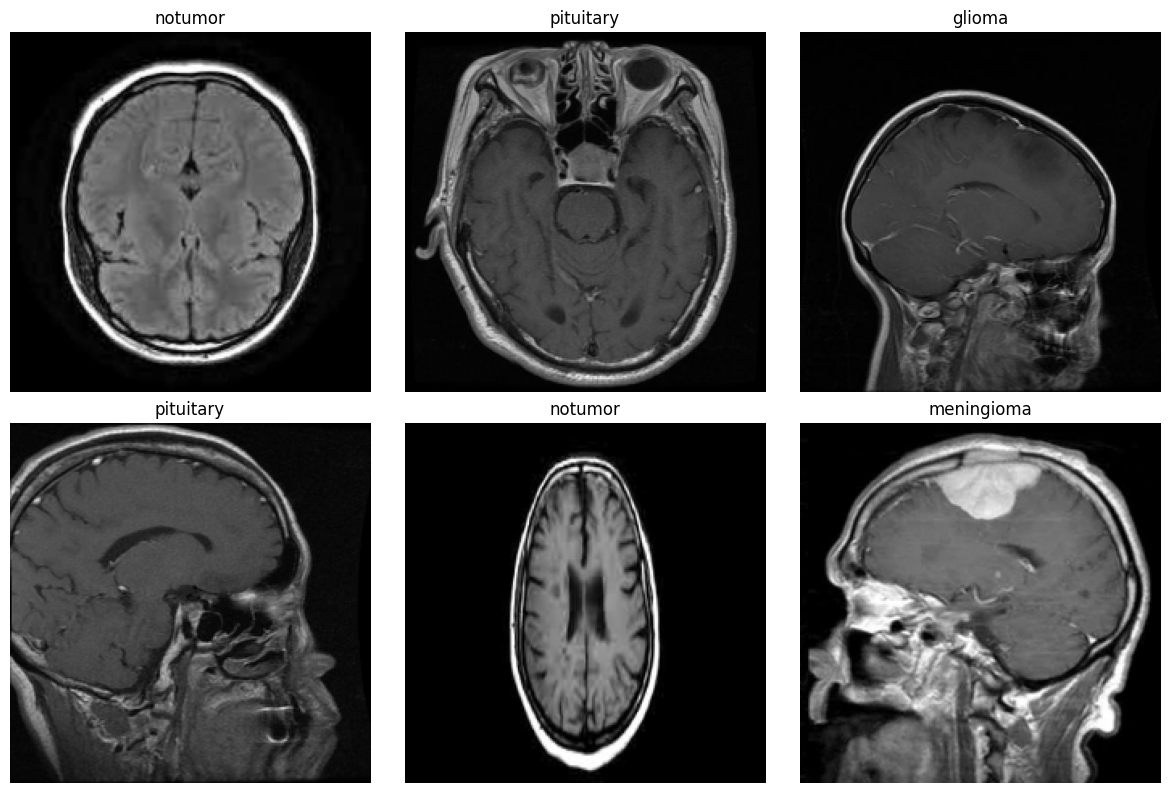

In [11]:
preview_images, preview_labels = next(iter(full_dataset))

fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, image, label in zip(
    axes.flat,
    preview_images[:6],
    preview_labels[:6],
):
    ax.imshow(image.numpy())
    ax.set_title(CLASSES[int(label.numpy())])
    ax.axis("off")

plt.tight_layout()
plt.show()

In [13]:
print(full_dataset.element_spec)

(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.uint8, name=None), TensorSpec(shape=(None,), dtype=tf.int64, name=None))


In [14]:
batch_images, batch_labels = next(iter(full_dataset))

print("Images shape:", batch_images.shape)
print("Images dtype:", batch_images.dtype)
print("Labels shape:", batch_labels.shape)
print("Labels dtype:", batch_labels.dtype)
print("Pixel range:", batch_images.numpy().min(), batch_images.numpy().max())
print("Labels in batch:", np.unique(batch_labels.numpy()))

Images shape: (32, 224, 224, 3)
Images dtype: <dtype: 'uint8'>
Labels shape: (32,)
Labels dtype: <dtype: 'int64'>
Pixel range: 0 255
Labels in batch: [0 1 2 3]


In [18]:
all_labels = [label for _, label in samples]

train_val_samples, test_samples = train_test_split(
    samples,
    test_size=0.15,
    random_state=RANDOM_STATE,
    stratify=all_labels,
)

In [24]:
train_val_labels = [
    label for _, label in train_val_samples
]

validation_fraction = 0.15 / 0.85

train_samples, val_samples = train_test_split(
    train_val_samples,
    test_size=validation_fraction,
    random_state=RANDOM_STATE,
    stratify=train_val_labels,
)

In [26]:
train_ds = make_dataset(
    train_samples,
    training=True,
)

val_ds = make_dataset(
    val_samples,
    training=False,
)

test_ds = make_dataset(
    test_samples,
    training=False,
)

In [31]:
def preprocess_for_mobilenet(images, labels):
    images = tf.cast(images, tf.float32)

    images = (
        tf.keras.applications.mobilenet_v2.preprocess_input(
            images
        )
    )

    return images, labels


sample_images, sample_labels = next(iter(train_ds))

processed_images, processed_labels = (
    preprocess_for_mobilenet(
        sample_images,
        sample_labels,
    )
)

In [33]:
def prepare_for_mobilenet(dataset):
    dataset = dataset.map(
        preprocess_for_mobilenet,
        num_parallel_calls=tf.data.AUTOTUNE,
    )

    return dataset.prefetch(tf.data.AUTOTUNE)

train_model_ds = prepare_for_mobilenet(train_ds)
val_model_ds = prepare_for_mobilenet(val_ds)
test_model_ds = prepare_for_mobilenet(test_ds)

In [39]:
data_augmentation = tf.keras.Sequential(
    [
        tf.keras.layers.RandomRotation(
            factor=0.03,
            fill_mode="reflect",
            seed=RANDOM_STATE,
        ),
        tf.keras.layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05,
            fill_mode="reflect",
            seed=RANDOM_STATE,
        ),
        tf.keras.layers.RandomZoom(
            height_factor=(-0.05, 0.05),
            width_factor=None,
            fill_mode="reflect",
            seed=RANDOM_STATE,
        ),
    ],
    name="mri_augmentation",
)

raw_images, raw_labels = next(iter(train_ds))

augmented_images = data_augmentation(
    raw_images,
    training=True,
)

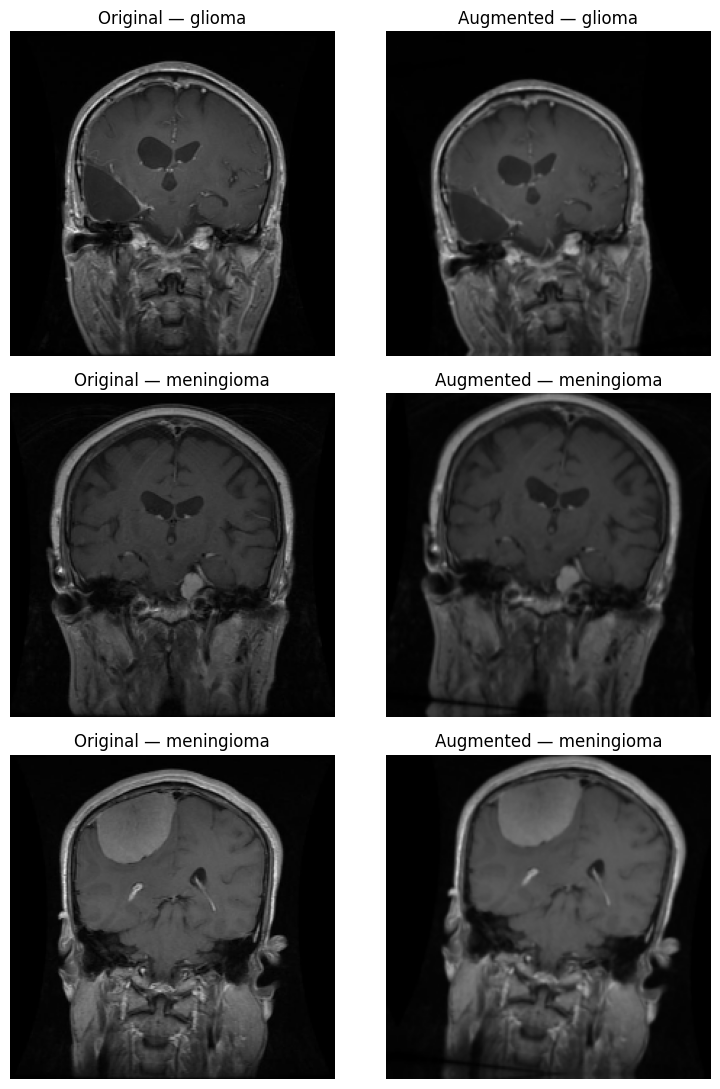

In [40]:
fig, axes = plt.subplots(3, 2, figsize=(8, 11))

for row in range(3):
    label = int(raw_labels[row].numpy())

    axes[row, 0].imshow(raw_images[row].numpy())
    axes[row, 0].set_title(
        f"Original — {CLASSES[label]}"
    )
    axes[row, 0].axis("off")

    axes[row, 1].imshow(
        tf.cast(augmented_images[row], tf.uint8).numpy()
    )
    axes[row, 1].set_title(
        f"Augmented — {CLASSES[label]}"
    )
    axes[row, 1].axis("off")

plt.tight_layout()
plt.show()

In [43]:
def prepare_for_mobilenet(dataset, augment=False):
    def transform(images, labels):
        if augment:
            images = data_augmentation(
                images,
                training=True,
            )
        return preprocess_for_mobilenet(
            images,
            labels,
        )
    dataset = dataset.map(
        transform,
        num_parallel_calls=tf.data.AUTOTUNE,
    )
    return dataset.prefetch(tf.data.AUTOTUNE)


train_model_ds = prepare_for_mobilenet(
    train_ds,
    augment=True,
)

val_model_ds = prepare_for_mobilenet(
    val_ds,
    augment=False,
)

test_model_ds = prepare_for_mobilenet(
    test_ds,
    augment=False,
)

train_images, train_labels = next(
    iter(train_model_ds)
)